<a href="https://colab.research.google.com/github/Abdoulaye279/Quantum-Computing/blob/main/06_molmer_sorensen_paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 - Mølmer-Sørensen gate, back to the paper

Sørensen & Mølmer, "Quantum computation with ions in thermal motion", PRL 82, 1971 (1999), quant-ph/9810039.

In 04 the MS gate was only at first order in the Lamb-Dicke parameter. Here the full Hamiltonian of the paper (Eq. 1, all orders in eta), with their parameters: delta = 0.9 nu, Omega = 0.1 nu, eta = 0.1. Ion 1 is driven at +delta from the carrier, ion 2 at -delta. Time in units of 1/nu. Uses QuTiP.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !pip install -q qutip
    !git clone -q https://github.com/Abdoulaye279/Quantum-Computing
    %cd Quantum-Computing
except ImportError:
    pass

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"   # much faster for these small matrices
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
plt.style.use("quant.mplstyle")

nu, delta, Om, eta = 1.0, 0.9, 0.1, 0.1
Nph = 16   # phonon levels kept

a = qt.tensor(qt.qeye(2), qt.qeye(2), qt.destroy(Nph))
sp1 = qt.tensor(qt.sigmap(), qt.qeye(2), qt.qeye(Nph))
sp2 = qt.tensor(qt.qeye(2), qt.sigmap(), qt.qeye(Nph))
D = (1j * eta * (a + a.dag())).expm()   # e^{i eta (a + a+)}, no Lamb-Dicke expansion
A1, A2 = Om / 2 * sp1 * D, Om / 2 * sp2 * D

def phase(s):
    return lambda t: np.exp(1j * s * delta * t)

# frame rotating at the qubit frequency: H = nu a+a + sum_i Omega/2 (s+_i D e^{-i delta_i t} + h.c.)
H = [nu * a.dag() * a, [A1, phase(-1)], [A1.dag(), phase(1)], [A2, phase(1)], [A2.dag(), phase(-1)]]

e, g = qt.basis(2, 0), qt.basis(2, 1)   # qutip: sigmap = |e><g| with e = basis 0
gg, ee = qt.tensor(g, g), qt.tensor(e, e)
P_gg = qt.tensor(gg * gg.dag(), qt.qeye(Nph))
P_ee = qt.tensor(ee * ee.dag(), qt.qeye(Nph))
coh = qt.tensor(ee * gg.dag(), qt.qeye(Nph))   # expectation = rho_gg,ee in the paper's notation
opt = {"nsteps": 10**7, "progress_bar": False}

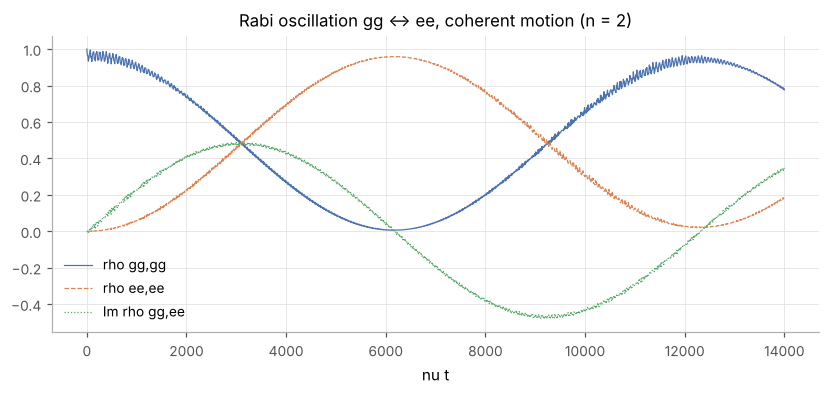

max P(ee) 0.96 at nu t = 6060.0
pi / Omega~: Eq. 3 6283   footnote 10 5969
max |Re rho gg,ee| 0.023


In [3]:
# Fig. 2 of the paper: both ions in g, vibration in a coherent state with mean n = 2
ts = np.linspace(0, 14000, 1401)
r = qt.sesolve(H, qt.tensor(gg, qt.coherent(Nph, np.sqrt(2))), ts, e_ops=[P_gg, P_ee, coh], options=opt)
pgg, pee, c = r.expect

plt.figure(figsize=(9, 3.5))
plt.plot(ts, pgg, lw=0.8, label="rho gg,gg")
plt.plot(ts, pee, "--", lw=0.8, label="rho ee,ee")
plt.plot(ts, c.imag, ":", lw=0.8, label="Im rho gg,ee")
plt.xlabel("nu t"); plt.legend(); plt.title("Rabi oscillation gg <-> ee, coherent motion (n = 2)")
plt.show()

Om_eq3 = (Om * eta) ** 2 / (2 * (nu - delta))           # Eq. 3
Om_fn10 = (Om * eta) ** 2 / ((nu**2 - delta**2) / nu)   # footnote 10, both sidebands kept
print("max P(ee)", round(pee.max(), 3), "at nu t =", ts[np.argmax(pee)])
print("pi / Omega~: Eq. 3", round(np.pi / Om_eq3), "  footnote 10", round(np.pi / Om_fn10))
print("max |Re rho gg,ee|", round(abs(c.real).max(), 3))
# same picture as the paper: gg and ee swap, Im(rho gg,ee) goes to +-0.5 halfway = maximally entangled state
# transfer at 6060, between Eq. 3 (6283) and footnote 10 (5969); Re stays below 0.03 like they say
# the small fast wiggles are the off-resonant couplings gg -> eg, ge, they shrink with Omega

In [4]:
# the point of the paper: the effective Rabi frequency should not depend on n
ts = np.linspace(0, 7000, 701)
print("Fock n   max P(ee)   at nu t")
for n0 in range(6):
    pe = qt.sesolve(H, qt.tensor(gg, qt.basis(Nph, n0)), ts, e_ops=[P_ee], options=opt).expect[0]
    print(f"  {n0}      {pe.max():.3f}      {ts[np.argmax(pe)]:.0f}")
# 95-99% transfer whatever n. for comparison the Cirac-Zoller gate in 04 falls to 0.33 with n = 2
# not perfectly n-independent though: the transfer time drifts from ~5800 (n = 0) to ~6900 (n = 5)
# Eq. 3 is second order in eta, so probably the higher-order eta terms of the full Hamiltonian

Fock n   max P(ee)   at nu t


  0      0.988      5780


  1      0.979      5940


  2      0.973      6160


  3      0.968      6450


  4      0.964      6670


  5      0.960      6890


jumps per trajectory: mean 32.25  min 8  max 99


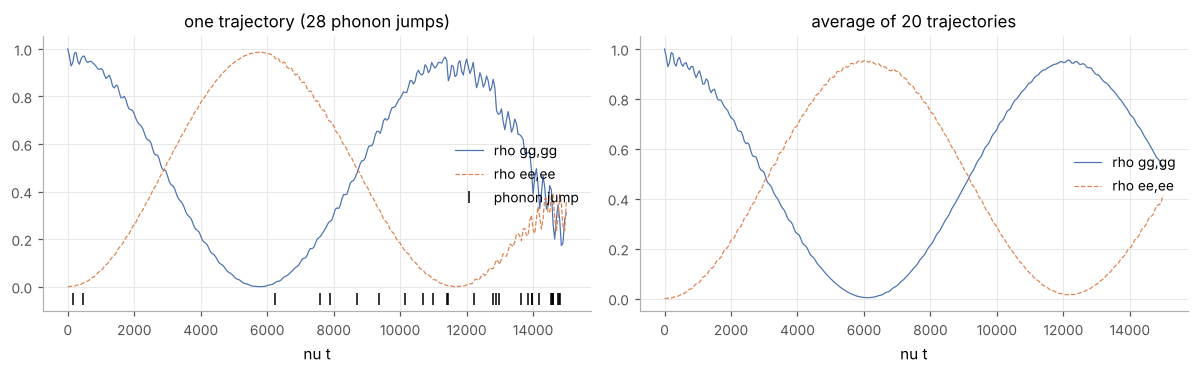

max P(ee) with heating 0.954


In [5]:
# Fig. 4: heating trap. relaxation ops sqrt(G (1+nth)) a and sqrt(G nth) a+, G = 2e-4 nu, nth = 2
G, nth = 2e-4, 2
ts = np.linspace(0, 15000, 301)
c_ops = [np.sqrt(G * (1 + nth)) * a, np.sqrt(G * nth) * a.dag()]
r = qt.mcsolve(H, qt.tensor(gg, qt.basis(Nph, 2)), ts, c_ops, e_ops=[P_gg, P_ee, a.dag() * a], ntraj=20, seeds=1,
               options={**opt, "keep_runs_results": True})
jumps = [len(t) for t in r.col_times]
print("jumps per trajectory: mean", np.mean(jumps), " min", min(jumps), " max", max(jumps))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ts, r.runs_expect[0][0], lw=0.8, label="rho gg,gg"); ax[0].plot(ts, r.runs_expect[1][0], "--", lw=0.8, label="rho ee,ee")
ax[0].plot(r.col_times[0], np.full(len(r.col_times[0]), -0.05), "|", color="k", ms=8, label="phonon jump")
ax[0].set_title(f"one trajectory ({jumps[0]} phonon jumps)"); ax[0].set_xlabel("nu t"); ax[0].legend()
ax[1].plot(ts, r.average_expect[0], lw=0.8, label="rho gg,gg"); ax[1].plot(ts, r.average_expect[1], "--", lw=0.8, label="rho ee,ee")
ax[1].set_title("average of 20 trajectories"); ax[1].set_xlabel("nu t"); ax[1].legend()
plt.tight_layout(); plt.show()
print("max P(ee) with heating", round(r.average_expect[1].max(), 3))
# 32 jumps per trajectory on average (paper: 34), so dozens of phonons exchanged with the reservoir, and the
# oscillation is still there: the vibration is only used virtually, so the jumps barely matter
# not free though: in the trajectory on the left the jumps pile up at the end, the motion gets hot and the
# oscillation gets noisy (larger n -> the eta^2 n corrections seen above). averaged: 0.95 instead of 0.97
# the Cirac-Zoller gate puts real population in the bus and would not survive a single jump in the middle

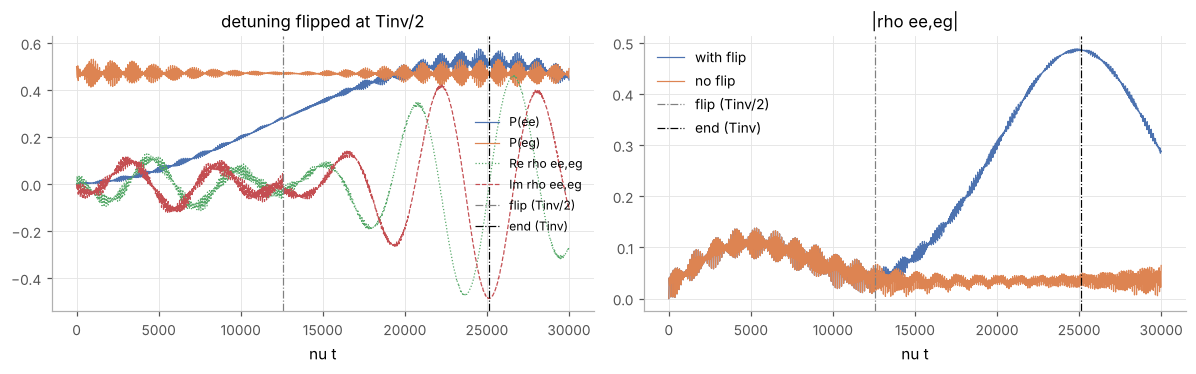

Tinv = 25133  rho ee,eg at Tinv: with flip (-0.011-0.485j)  without (0.014-0.02j)


In [6]:
# Fig. 3: echo. ion 1 in (g + e)/sqrt2, ion 2 in g. eg and ge get an n-dependent phase (Eq. 4) that scrambles
# the coherence; flipping the sign of delta at Tinv/2 makes that phase run backwards. Omega = 0.05 nu here
Om3 = 0.05
B1, B2 = Om3 / 2 * sp1 * D, Om3 / 2 * sp2 * D
Tinv = 2 * np.pi * (nu - delta) / (eta * Om3) ** 2

def H_echo(flip):
    # laser phase = integral of the detuning, so it stays continuous when the sign flips
    ph = (lambda t: delta * t if t < Tinv / 2 else delta * (Tinv - t)) if flip else (lambda t: delta * t)
    return [nu * a.dag() * a, [B1, lambda t: np.exp(-1j * ph(t))], [B1.dag(), lambda t: np.exp(1j * ph(t))],
            [B2, lambda t: np.exp(1j * ph(t))], [B2.dag(), lambda t: np.exp(-1j * ph(t))]]

eg = qt.tensor(e, g)
ops = [P_ee, qt.tensor(eg * eg.dag(), qt.qeye(Nph)), qt.tensor(eg * ee.dag(), qt.qeye(Nph))]   # last = rho ee,eg
psi0 = qt.tensor((g + e).unit(), g, qt.coherent(Nph, np.sqrt(2)))
ts = np.linspace(0, 30000, 1201)
res = {flip: qt.sesolve(H_echo(flip), psi0, ts, e_ops=ops, options={**opt, "max_step": 2.0}).expect for flip in [True, False]}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pee, peg, c = res[True]
ax[0].plot(ts, pee, lw=0.8, label="P(ee)"); ax[0].plot(ts, peg, lw=0.8, label="P(eg)")
ax[0].plot(ts, c.real, ":", lw=0.8, label="Re rho ee,eg"); ax[0].plot(ts, c.imag, "--", lw=0.8, label="Im rho ee,eg")
ax[0].axvline(Tinv / 2, color="gray", ls="-.", lw=0.8, label="flip (Tinv/2)"); ax[0].axvline(Tinv, color="k", ls="-.", lw=0.8, label="end (Tinv)")
ax[0].set_title("detuning flipped at Tinv/2"); ax[0].set_xlabel("nu t"); ax[0].legend(fontsize=8)
ax[1].plot(ts, abs(res[True][2]), lw=0.8, label="with flip"); ax[1].plot(ts, abs(res[False][2]), lw=0.8, label="no flip")
ax[1].axvline(Tinv / 2, color="gray", ls="-.", lw=0.8, label="flip (Tinv/2)"); ax[1].axvline(Tinv, color="k", ls="-.", lw=0.8, label="end (Tinv)")
ax[1].set_title("|rho ee,eg|"); ax[1].set_xlabel("nu t"); ax[1].legend()
plt.tight_layout(); plt.show()
i = np.argmin(abs(ts - Tinv))
print("Tinv =", round(Tinv), " rho ee,eg at Tinv: with flip", np.round(res[True][2][i], 3), " without", np.round(res[False][2][i], 3))
# with the flip the coherence comes back at Tinv: rho ee,eg = -0.485i, the target (-i|ee> + |eg>)/sqrt2 gives -0.5i
# without it the populations still swap but the coherence is gone (0.02): the phase depends on n and the
# motion is in a superposition of n, so it averages out
# the catch (paper): a phonon jump before the flip breaks the echo, hence the bichromatic version used above